# Fase 1 — Exploración de datos (Sen1Floods11)

**Objetivo:** entender los datos antes de diseñar nada. Al final de esta fase tendremos:
1. Cómo se reparten los eventos entre particiones.
2. El desbalance agua / no agua (decide la función de pérdida).
3. Cómo se ve el agua en VV y VH (justifica por qué el SAR sirve).
4. Estadísticas de normalización (las usa la fase 2).
5. **Cuánto ruido tiene la etiqueta débil (Otsu)** frente a la dorada → argumento central de la ablación (a).

## Teoría mínima: ¿qué estamos mirando?
- **SAR** (radar de apertura sintética) emite microondas y mide cuánta energía **regresa** al satélite: la *retrodispersión* (σ⁰). No depende del sol ni de las nubes.
- Se expresa en **decibeles**: σ⁰(dB) = 10·log₁₀(σ⁰). Valores más negativos = menos energía de vuelta = píxel más oscuro.
- **Polarización:** **VV** emite y recibe en vertical (sensible a superficies y rugosidad); **VH** emite vertical y recibe horizontal (sensible a dispersión de volumen: vegetación).
- **Agua en calma = espejo:** refleja el pulso *lejos* del sensor (reflexión especular) → retrodispersión muy baja → **el agua se ve negra**. Esa es la física que explota tanto Otsu (un umbral) como nuestra U-Net.
- Excepciones que veremos en la fase 9: viento que riza el agua, sombra de radar (también negra pero sin agua), y **doble rebote** en ciudades inundadas (agua + pared = muy brillante).

## 0. Preparación

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import sys
from pathlib import Path
RAIZ_PROYECTO = Path('/content/drive/MyDrive/rnap_p2_inundaciones')
sys.path.insert(0, str(RAIZ_PROYECTO))

!pip install -q rasterio

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Módulos nuevos de `src/`
Cada celda escribe un archivo directo en tu Drive (`%%writefile`). Córrelas una vez; si luego cambio algo, solo re-ejecutas la celda de ese módulo.
- `descarga.py` → baja los datos si faltan (útil al inicio de cada sesión).
- `lectura.py` → lee particiones y chips.
- `metricas.py` → IoU, F1, precisión, recall, omisión, comisión (se reutiliza en todas las fases).
- `exploracion.py` → funciones de esta fase.
- `visualizacion.py` → figuras.

In [3]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/descarga.py
"""
descarga.py
Descarga de Sen1Floods11 desde el bucket público al disco local de Colab.
Se llama al inicio de cada notebook: si los datos ya están, no hace nada.
"""
import subprocess

from .configuracion import (BUCKET, DIR_S1_MANO, DIR_ETIQUETA_MANO, DIR_OTSU_MANO,
                            DIR_S2_MANO, DIR_S1_DEBIL, DIR_ETIQUETA_DEBIL, DIR_PARTICIONES)

_ORIGENES = {
    DIR_S1_MANO:        "data/flood_events/HandLabeled/S1Hand",
    DIR_ETIQUETA_MANO:  "data/flood_events/HandLabeled/LabelHand",
    DIR_OTSU_MANO:      "data/flood_events/HandLabeled/S1OtsuLabelHand",
    DIR_PARTICIONES:    "splits/flood_handlabeled",
    DIR_S2_MANO:        "data/flood_events/HandLabeled/S2Hand",
    DIR_S1_DEBIL:       "data/flood_events/WeaklyLabeled/S1Weak",
    DIR_ETIQUETA_DEBIL: "data/flood_events/WeaklyLabeled/S1OtsuLabelWeak",
}


def _descargar(destino) -> None:
    if destino.exists() and any(destino.iterdir()):
        print(f"[ya existe] {destino.name}")
        return
    destino.parent.mkdir(parents=True, exist_ok=True)
    print(f"[descargando] {destino.name} ...")
    subprocess.run(["gsutil", "-m", "-q", "cp", "-r", f"{BUCKET}/{_ORIGENES[destino]}",
                    str(destino.parent)], check=True)


def descargar_mano() -> None:
    """Chips etiquetados a mano (S1, etiqueta dorada, etiqueta Otsu) + particiones."""
    for destino in [DIR_S1_MANO, DIR_ETIQUETA_MANO, DIR_OTSU_MANO, DIR_PARTICIONES]:
        _descargar(destino)


def descargar_debil() -> None:
    """Chips con etiqueta débil (~9 GB). Recién en la fase 6."""
    for destino in [DIR_S1_DEBIL, DIR_ETIQUETA_DEBIL]:
        _descargar(destino)


def descargar_s2_mano() -> None:
    """Óptico Sentinel-2 de los chips a mano. Solo para el bono (fase 10)."""
    _descargar(DIR_S2_MANO)


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/descarga.py


In [4]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/lectura.py
"""
lectura.py
Lectura de particiones y de chips GeoTIFF de Sen1Floods11.
Convención de nombres: {Evento}_{idChip}_{Capa}.tif   ej. Bolivia_103757_S1Hand.tif
"""
import numpy as np
import pandas as pd
import rasterio

from .configuracion import DIR_PARTICIONES, DIR_S1_MANO, DIR_ETIQUETA_MANO, DIR_OTSU_MANO

PARTICIONES = ["train", "valid", "test", "bolivia"]


def leer_particion(nombre: str) -> pd.DataFrame:
    """Devuelve un DataFrame con id_chip, evento y partición a partir del CSV oficial."""
    ruta = DIR_PARTICIONES / f"flood_{nombre}_data.csv"
    df = pd.read_csv(ruta, header=None, names=["archivo_s1", "archivo_etiqueta"])
    df["id_chip"] = df["archivo_s1"].str.replace("_S1Hand.tif", "", regex=False)
    df["evento"] = df["id_chip"].str.split("_").str[0]
    df["particion"] = nombre
    return df[["id_chip", "evento", "particion"]]


def leer_todas_las_particiones() -> pd.DataFrame:
    return pd.concat([leer_particion(p) for p in PARTICIONES], ignore_index=True)


def leer_tif(ruta) -> np.ndarray:
    with rasterio.open(ruta) as src:
        return src.read()          # (bandas, alto, ancho)


def leer_s1(id_chip: str, carpeta=DIR_S1_MANO, sufijo: str = "S1Hand") -> np.ndarray:
    """SAR Sentinel-1: (2, 512, 512) float32 -> banda 0 = VV, banda 1 = VH, en dB."""
    return leer_tif(carpeta / f"{id_chip}_{sufijo}.tif").astype(np.float32)


def leer_etiqueta(id_chip: str, carpeta=DIR_ETIQUETA_MANO, sufijo: str = "LabelHand") -> np.ndarray:
    """Máscara (512, 512) int16: -1 sin dato, 0 no agua, 1 agua."""
    return leer_tif(carpeta / f"{id_chip}_{sufijo}.tif")[0].astype(np.int16)


def leer_otsu(id_chip: str) -> np.ndarray:
    """Etiqueta automática por umbral de Otsu sobre el MISMO chip (la 'etiqueta débil')."""
    return leer_etiqueta(id_chip, DIR_OTSU_MANO, "S1OtsuLabelHand")


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/lectura.py


In [5]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/metricas.py
"""
metricas.py
Métricas de segmentación binaria para la clase "agua" a partir de conteos de la matriz de confusión.
Siempre se calculan SOLO sobre píxeles válidos (etiqueta != -1).
"""
import numpy as np


def conteos_confusion(prediccion: np.ndarray, referencia: np.ndarray, validos: np.ndarray) -> dict:
    """prediccion/referencia: arrays binarios {0,1}; validos: máscara booleana."""
    p = prediccion[validos].astype(bool)
    r = referencia[validos].astype(bool)
    return {
        "vp": int(np.sum(p & r)),     # verdaderos positivos (agua bien detectada)
        "fp": int(np.sum(p & ~r)),    # falsos positivos (dice agua y no es)
        "fn": int(np.sum(~p & r)),    # falsos negativos (agua no detectada)
        "vn": int(np.sum(~p & ~r)),   # verdaderos negativos
    }


def metricas_desde_conteos(vp: int, fp: int, fn: int, vn: int) -> dict:
    eps = 1e-9
    precision = vp / (vp + fp + eps)
    recall = vp / (vp + fn + eps)
    return {
        "iou": vp / (vp + fp + fn + eps),
        "f1": 2 * precision * recall / (precision + recall + eps),
        "precision": precision,
        "recall": recall,
        "omision": fn / (vp + fn + eps),     # = 1 - recall   (agua que se nos escapó)
        "comision": fp / (vp + fp + eps),    # = 1 - precision (agua inventada)
        "exactitud": (vp + vn) / (vp + fp + fn + vn + eps),
    }


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/metricas.py


In [6]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/exploracion.py
"""
exploracion.py
Funciones del análisis exploratorio (fase 1): balance de clases, estadísticas SAR
y ruido de la etiqueta débil (Otsu) frente a la dorada (mano).
"""
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from .configuracion import VALOR_SIN_DATO
from .lectura import leer_s1, leer_etiqueta, leer_otsu
from .metricas import conteos_confusion


def resumen_chip(id_chip: str) -> dict:
    s1 = leer_s1(id_chip)
    etiqueta = leer_etiqueta(id_chip)
    otsu = leer_otsu(id_chip)

    s1_finito = np.isfinite(s1).all(axis=0)
    validos = (etiqueta != VALOR_SIN_DATO) & (otsu != VALOR_SIN_DATO) & s1_finito

    fila = {
        "id_chip": id_chip,
        "px_agua": int(np.sum(etiqueta == 1)),
        "px_no_agua": int(np.sum(etiqueta == 0)),
        "px_sin_dato": int(np.sum(etiqueta == VALOR_SIN_DATO)),
        "px_s1_no_finito": int(np.sum(~s1_finito)),
    }
    fila.update(conteos_confusion(otsu == 1, etiqueta == 1, validos))
    return fila


def tabla_resumen(df_chips: pd.DataFrame) -> pd.DataFrame:
    ids_unicos = df_chips["id_chip"].unique()
    filas = [resumen_chip(i) for i in tqdm(ids_unicos, desc="Resumiendo chips")]
    return df_chips.merge(pd.DataFrame(filas), on="id_chip", validate="many_to_one")


def muestrear_pixeles(ids_chips, n_por_clase: int = 2000, semilla: int = 42,
                      balanceado: bool = True) -> pd.DataFrame:
    """Devuelve un DataFrame (vv, vh, clase) con píxeles muestreados de cada chip.
    - balanceado=True : hasta n píxeles de agua y n de no agua por chip (para comparar las
                        DISTRIBUCIONES de cada clase en los histogramas).
    - balanceado=False: n píxeles válidos al azar por chip, respetando la proporción real
                        de clases (para estadísticas de normalización sin sesgo).
    Muestrear evita cargar 446 x 262k píxeles en memoria."""
    generador = np.random.default_rng(semilla)
    partes = []
    for id_chip in tqdm(ids_chips, desc="Muestreando píxeles"):
        s1 = leer_s1(id_chip)
        etiqueta = leer_etiqueta(id_chip)
        finito = np.isfinite(s1).all(axis=0)
        grupos = [(etiqueta == 0) & finito, (etiqueta == 1) & finito] if balanceado \
            else [(etiqueta != VALOR_SIN_DATO) & finito]
        for mascara in grupos:
            filas, columnas = np.where(mascara)
            if len(filas) == 0:
                continue
            elegidos = generador.choice(len(filas), size=min(n_por_clase, len(filas)), replace=False)
            f, c = filas[elegidos], columnas[elegidos]
            partes.append(pd.DataFrame({"vv": s1[0, f, c], "vh": s1[1, f, c], "clase": etiqueta[f, c]}))
    return pd.concat(partes, ignore_index=True)


def estadisticas_bandas(df_pixeles: pd.DataFrame) -> dict:
    """Percentiles, media y desviación por banda (para normalizar en la fase 2)."""
    resultado = {}
    for banda in ["vv", "vh"]:
        valores = df_pixeles[banda].to_numpy()
        resultado[banda] = {
            "p1": float(np.percentile(valores, 1)),
            "p99": float(np.percentile(valores, 99)),
            "media": float(valores.mean()),
            "desviacion": float(valores.std()),
        }
    return resultado


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/exploracion.py


In [7]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/visualizacion.py
"""
visualizacion.py
Figuras reutilizables (exploración ahora; predicciones y fallos en fases posteriores).
"""
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap, BoundaryNorm

# -1 sin dato (gris), 0 no agua (arena), 1 agua (azul)
MAPA_ETIQUETA = ListedColormap(["#9e9e9e", "#efe6d2", "#1f5fbf"])
NORMA_ETIQUETA = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], MAPA_ETIQUETA.N)
RANGO_DB = {"VV": (-25, 0), "VH": (-32, -5)}   # rango de visualización típico en dB


def mostrar_mascara(eje, mascara, titulo):
    eje.imshow(mascara, cmap=MAPA_ETIQUETA, norm=NORMA_ETIQUETA, interpolation="nearest")
    eje.set_title(titulo, fontsize=9)
    eje.axis("off")


def mostrar_sar(eje, banda, nombre):
    vmin, vmax = RANGO_DB[nombre]
    eje.imshow(np.nan_to_num(banda, nan=vmin), cmap="gray", vmin=vmin, vmax=vmax)
    eje.set_title(f"{nombre} (dB)", fontsize=9)
    eje.axis("off")


def figura_chips(lista_chips, ruta_guardado=None):
    """lista_chips: [(id_chip, s1, etiqueta, otsu), ...] -> una fila por chip."""
    figura, ejes = plt.subplots(len(lista_chips), 4, figsize=(12, 3.1 * len(lista_chips)))
    ejes = np.atleast_2d(ejes)
    for fila, (id_chip, s1, etiqueta, otsu) in enumerate(lista_chips):
        mostrar_sar(ejes[fila, 0], s1[0], "VV")
        mostrar_sar(ejes[fila, 1], s1[1], "VH")
        mostrar_mascara(ejes[fila, 2], etiqueta, "Etiqueta dorada (mano)")
        mostrar_mascara(ejes[fila, 3], otsu, "Etiqueta débil (Otsu)")
        ejes[fila, 0].text(-0.08, 0.5, id_chip, transform=ejes[fila, 0].transAxes,
                           rotation=90, va="center", ha="right", fontsize=9)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


def figura_histogramas(df_pixeles, ruta_guardado=None):
    """Distribución de retrodispersión (dB) para agua vs no agua, por banda."""
    figura, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
    for eje, banda in zip(ejes, ["vv", "vh"]):
        for clase, color, nombre in [(0, "#b08d57", "No agua"), (1, "#1f5fbf", "Agua")]:
            valores = df_pixeles.loc[df_pixeles["clase"] == clase, banda]
            eje.hist(valores, bins=120, range=(-40, 5), density=True, alpha=0.6,
                     color=color, label=nombre)
        eje.set_xlabel(f"{banda.upper()} (dB)")
        eje.set_ylabel("Densidad")
        eje.legend()
        eje.grid(alpha=0.3)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/visualizacion.py


In [8]:
import json
import numpy as np
import pandas as pd

from src.configuracion import *
from src.utilidades import fijar_semilla
from src.descarga import descargar_mano
from src.lectura import leer_todas_las_particiones, leer_s1, leer_etiqueta, leer_otsu
from src.metricas import metricas_desde_conteos
from src.exploracion import tabla_resumen, muestrear_pixeles, estadisticas_bandas
from src.visualizacion import figura_chips, figura_histogramas

fijar_semilla(SEMILLA)
descargar_mano()   # si la sesión es nueva, vuelve a bajar los datos (~1-2 min)

[descargando] S1Hand ...
[descargando] LabelHand ...
[descargando] S1OtsuLabelHand ...
[descargando] flood_handlabeled ...


## 2. Eventos por partición
**Qué observar:** train/valid/test comparten los mismos eventos (por eso la evaluación del punto 3 del enunciado es *en distribución*); Bolivia solo aparece en su propia partición (es la región *no vista*).

In [9]:
df_chips = leer_todas_las_particiones()
tabla_eventos = pd.crosstab(df_chips['evento'], df_chips['particion'], margins=True, margins_name='Total')
tabla_eventos = tabla_eventos[[c for c in ['train', 'valid', 'test', 'bolivia', 'Total'] if c in tabla_eventos.columns]]
display(tabla_eventos)

particion,train,valid,test,bolivia,Total
evento,,,,,
Bolivia,0,0,0,15,15
Ghana,31,11,11,0,53
India,40,14,14,0,68
Mekong,18,6,6,0,30
Nigeria,10,4,4,0,18
Pakistan,16,6,6,0,28
Paraguay,39,14,14,0,67
Somalia,15,5,6,0,26
Spain,18,6,6,0,30


## 3. Resumen por chip (recorre los 446 chips, ~1 min)

In [10]:
df_resumen = tabla_resumen(df_chips)
df_resumen.to_csv(DIR_RESULTADOS / 'f1_resumen_chips.csv', index=False)
df_resumen.head()

Resumiendo chips:   0%|          | 0/446 [00:00<?, ?it/s]

,id_chip,evento,particion,px_agua,px_no_agua,px_sin_dato,px_s1_no_finito,vp,fp,fn,vn
0,Ghana_103272,Ghana,train,1558,257711,2875,0,1476,978,82,256733
1,Ghana_24858,Ghana,train,484,261660,0,0,0,0,484,261660
2,Ghana_147015,Ghana,train,3530,258614,0,0,9,0,3521,258614
3,Ghana_953791,Ghana,train,2772,259372,0,0,293,136,2479,259236
4,Ghana_154838,Ghana,train,0,42107,220037,0,0,0,0,42107


## 4. Balance de clases
**Qué observar:**
- `% agua (sobre válidos)`: si es bajo (≈10–15 %), una red que diga "todo es no agua" ya tendría ~85–90 % de exactitud → por eso **no usaremos exactitud** como métrica principal sino IoU, y por eso probaremos **Dice** en la ablación (b).
- `% sin dato`: píxeles que la pérdida y las métricas deben **ignorar**.
- `chips sin agua`: chips sin un solo píxel de agua (ojo con ellos en el IoU por chip).
- Variación entre eventos: unos eventos tendrán mucha más agua que otros.

In [11]:
def balance(df, por):
    g = df.groupby(por)[['px_agua', 'px_no_agua', 'px_sin_dato']].sum()
    total = g.sum(axis=1)
    salida = pd.DataFrame({
        'chips': df.groupby(por).size(),
        '% agua': 100 * g['px_agua'] / total,
        '% no agua': 100 * g['px_no_agua'] / total,
        '% sin dato': 100 * g['px_sin_dato'] / total,
        '% agua (sobre válidos)': 100 * g['px_agua'] / (g['px_agua'] + g['px_no_agua']),
    })
    salida['chips sin agua'] = df.assign(sin_agua=df['px_agua'] == 0).groupby(por)['sin_agua'].sum()
    return salida.round(2)

print('Por partición');  display(balance(df_resumen, 'particion'))
print('Por evento');     display(balance(df_resumen, 'evento').sort_values('% agua (sobre válidos)'))
print('Píxeles SAR no finitos (NaN/inf):', int(df_resumen['px_s1_no_finito'].sum()))

Por partición


,chips,% agua,% no agua,% sin dato,% agua (sobre válidos),chips sin agua
particion,,,,,,
bolivia,15,11.57,61.36,27.07,15.86,0
test,90,10.88,76.09,13.04,12.51,7
train,252,8.25,78.50,13.26,9.51,33
valid,89,9.59,77.40,13.01,11.03,12


Por evento


,chips,% agua,% no agua,% sin dato,% agua (sobre válidos),chips sin agua
evento,,,,,,
USA,69,4.45,93.11,2.44,4.56,0
Ghana,53,4.16,62.02,33.83,6.28,26
Somalia,26,5.13,73.73,21.13,6.51,4
Pakistan,28,5.49,67.76,26.75,7.50,7
Paraguay,67,7.97,87.00,5.04,8.39,10
Sri-Lanka,42,10.68,79.82,9.51,11.80,2
India,68,10.41,73.62,15.97,12.39,2
Spain,30,12.93,85.34,1.74,13.15,0
Bolivia,15,11.57,61.36,27.07,15.86,0


Píxeles SAR no finitos (NaN/inf): 2511705
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 5. ¿Cómo se ve el agua en el radar? (solo train)
**Qué observar:** la distribución del agua (azul) debería estar desplazada a valores **más negativos** que la de no agua, en ambas bandas. El **traslape** entre ambas curvas es justamente lo que un umbral simple (Otsu) no puede resolver y donde la U-Net debe aprovechar el **contexto espacial**.

Muestreando píxeles:   0%|          | 0/252 [00:00<?, ?it/s]

clase             0          1
vv count  501892.00  371675.00
   mean       -9.77     -15.31
   std         3.18       5.47
   min       -37.00     -47.30
   25%       -11.61     -19.58
   50%        -9.58     -14.92
   75%        -7.75     -11.01
   max        17.61      10.87
vh count  501892.00  371675.00
   mean      -16.41     -23.36
   std         3.52       6.12
   min       -52.04     -60.44
   25%       -18.25     -26.96
   50%       -16.03     -23.00
   75%       -14.12     -19.01
   max        10.83      -1.44


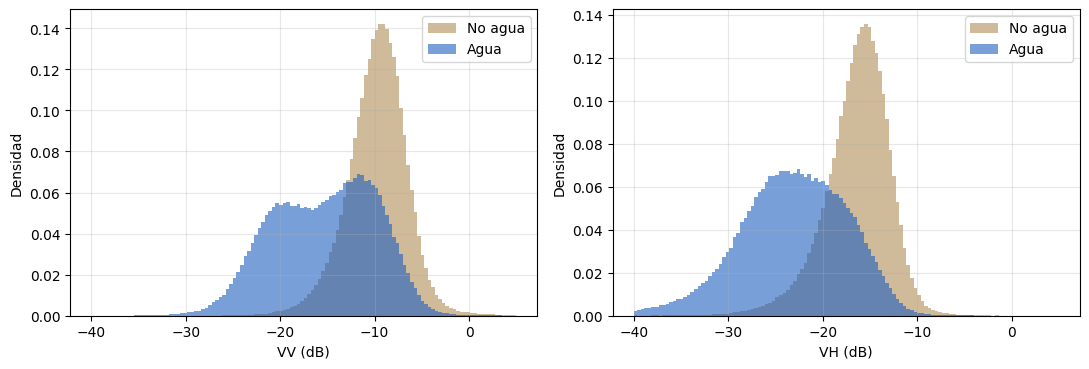

In [12]:
ids_entrenamiento = df_chips.loc[df_chips['particion'] == 'train', 'id_chip']
df_pixeles = muestrear_pixeles(ids_entrenamiento, n_por_clase=2000, semilla=SEMILLA)
print(df_pixeles.groupby('clase')[['vv', 'vh']].describe().T.round(2))
figura_histogramas(df_pixeles, DIR_FIGURAS / 'f1_histogramas_vv_vh.png');

## 6. Estadísticas para normalizar (fase 2)
Las redes entrenan mejor con entradas centradas y en escala similar. Guardamos percentiles (para recortar valores extremos) y media/desviación por banda.

In [13]:
# Solo con TRAIN: usar valid/test aquí sería fuga de información (data leakage).
# Muestreo NO balanceado: la red verá la proporción real de agua, así que normalizamos con ella.
df_pixeles_reales = muestrear_pixeles(ids_entrenamiento, n_por_clase=4000, semilla=SEMILLA, balanceado=False)
print(f"% agua en la muestra real: {100 * df_pixeles_reales['clase'].mean():.1f}%")
estadisticas = estadisticas_bandas(df_pixeles_reales)
with open(DIR_RESULTADOS / 'f1_estadisticas_normalizacion.json', 'w') as f:
    json.dump(estadisticas, f, indent=2)
pd.DataFrame(estadisticas).round(3)

Muestreando píxeles:   0%|          | 0/252 [00:00<?, ?it/s]

% agua en la muestra real: 9.4%


,vv,vh
p1,-24.034,-34.466
p99,-2.446,-9.531
media,-10.416,-17.267
desviacion,4.077,4.791


## 7. Ejemplos visuales

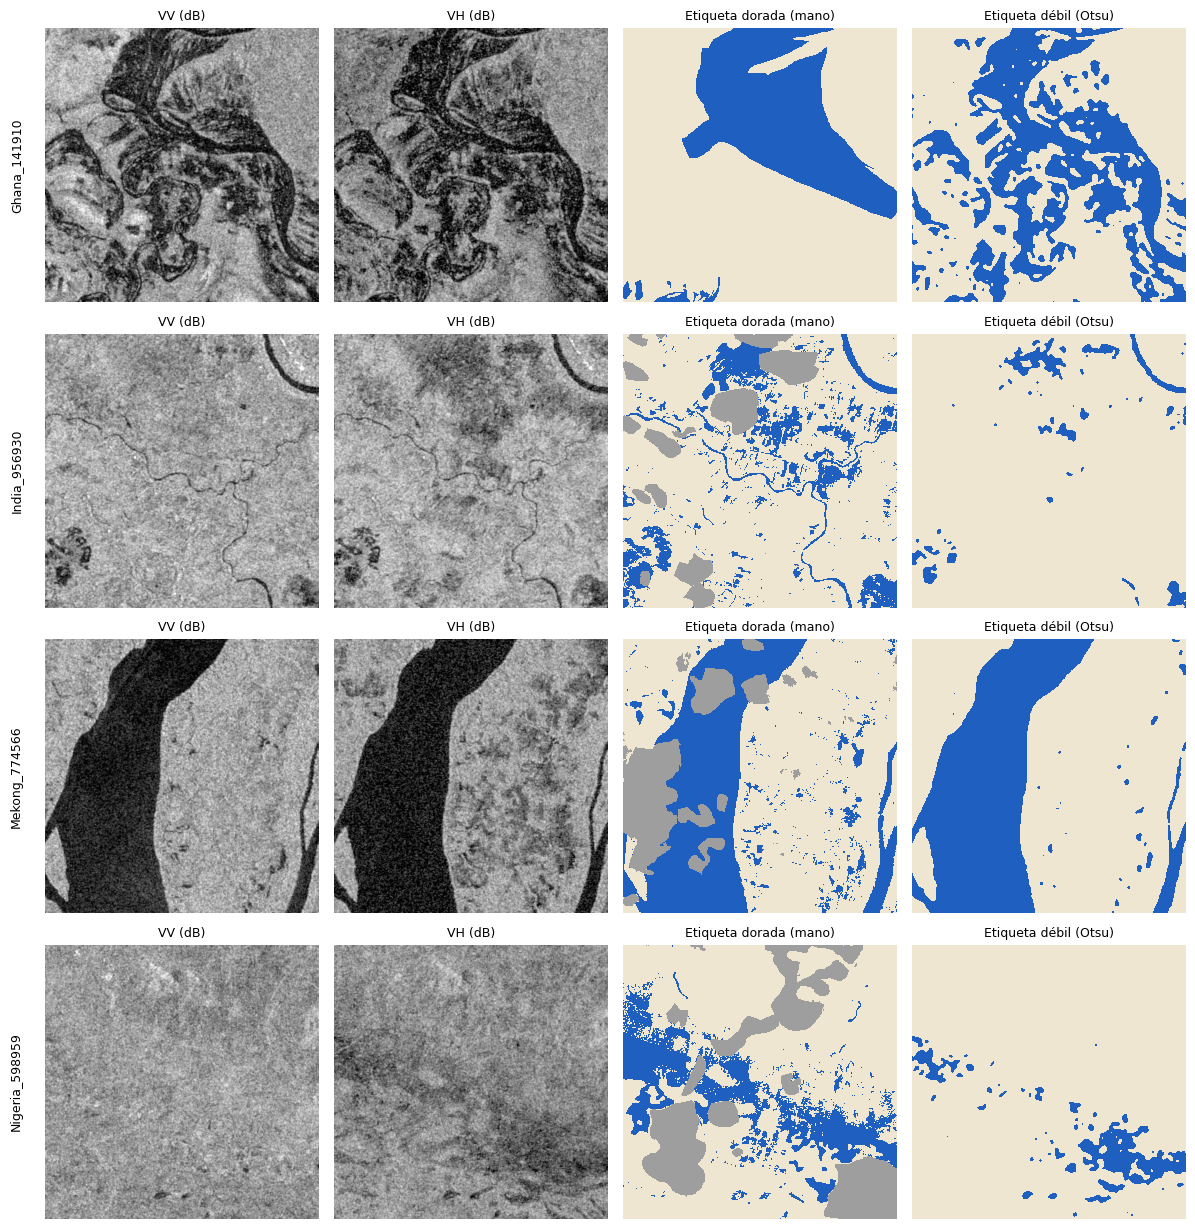

In [14]:
# Un chip por evento con fracción de agua intermedia (ni vacío ni lleno): son los más informativos
df_tmp = df_resumen[df_resumen['particion'] == 'train'].copy()
df_tmp['frac_agua'] = df_tmp['px_agua'] / (df_tmp['px_agua'] + df_tmp['px_no_agua']).clip(lower=1)
candidatos = df_tmp[(df_tmp['frac_agua'] > 0.15) & (df_tmp['frac_agua'] < 0.6)]
elegidos = candidatos.groupby('evento').head(1).head(4)['id_chip'].tolist()

figura_chips([(i, leer_s1(i), leer_etiqueta(i), leer_otsu(i)) for i in elegidos],
             DIR_FIGURAS / 'f1_ejemplos_chips.png');

## 8. Ruido de la etiqueta débil: Otsu vs. mano
Sobre los **mismos** 446 chips tenemos la etiqueta dorada y la de Otsu (mismo algoritmo con el que se generaron las 4,384 etiquetas débiles). Comparándolas **estimamos el ruido** de la supervisión débil.

**Qué observar:**
- **IoU global** de Otsu: es una *línea base* que la U-Net debe superar (si no la supera, no aporta nada sobre un umbral).
- **Omisión vs. comisión:** ¿Otsu se *pierde* agua o *inventa* agua? Eso dice qué sesgo aprendería la red de las etiquetas débiles.
- **Eventos con IoU bajo:** ahí la etiqueta débil es poco confiable.

In [15]:
def acuerdo(df, por=None):
    columnas = ['vp', 'fp', 'fn', 'vn']
    if por is None:
        return pd.DataFrame([metricas_desde_conteos(*df[columnas].sum())], index=['GLOBAL'])
    filas = {k: metricas_desde_conteos(*g[columnas].sum()) for k, g in df.groupby(por)}
    return pd.DataFrame(filas).T

# Ojo: cada chip una sola vez (por si algún id se repitiera)
df_unicos = df_resumen.drop_duplicates('id_chip')
ruido_global = acuerdo(df_unicos)
ruido_evento = acuerdo(df_unicos, 'evento').sort_values('iou')
display(ruido_global.round(3))
display(ruido_evento.round(3))
pd.concat([ruido_global, ruido_evento]).to_csv(DIR_RESULTADOS / 'f1_ruido_otsu_vs_mano.csv')

,iou,f1,precision,recall,omision,comision,exactitud
GLOBAL,0.495,0.662,0.617,0.715,0.285,0.383,0.923


,iou,f1,precision,recall,omision,comision,exactitud
Somalia,0.151,0.262,0.171,0.558,0.442,0.829,0.795
Pakistan,0.152,0.264,0.163,0.694,0.306,0.837,0.709
Ghana,0.408,0.580,0.807,0.453,0.547,0.193,0.959
Paraguay,0.448,0.619,0.478,0.878,0.122,0.522,0.912
USA,0.509,0.674,0.647,0.704,0.296,0.353,0.969
India,0.531,0.694,0.823,0.600,0.400,0.177,0.935
Nigeria,0.645,0.784,0.958,0.664,0.336,0.042,0.914
Sri-Lanka,0.649,0.787,0.806,0.769,0.231,0.194,0.951
Spain,0.670,0.802,0.928,0.706,0.294,0.072,0.954
Bolivia,0.718,0.836,0.803,0.871,0.129,0.197,0.945


## Para traer a la conversación
Pega la salida de: **tabla de eventos (2)**, **balance por partición y por evento (4)**, **estadísticas de normalización (6)** y **ruido Otsu vs. mano (8)**, más las dos figuras (histogramas y ejemplos). Con eso interpretamos y cerramos la fase.